In [4]:
%pip install pandas numpy matplotlib seaborn scikit-learn flask joblib requests

Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
import os
 
os.makedirs("AquaSense_AI", exist_ok=True) 
url = "https://raw.githubusercontent.com/Sarthak-1408/Water-Potability/main/water_potability.csv"

df = pd.read_csv(url)

df.to_csv("AquaSense_AI/water_potability.csv", index=False)
print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset downloaded successfully!
Dataset shape: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [6]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nPotability distribution:")
print(df["Potability"].value_counts())

Column names:
['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB

Missing values:
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            7

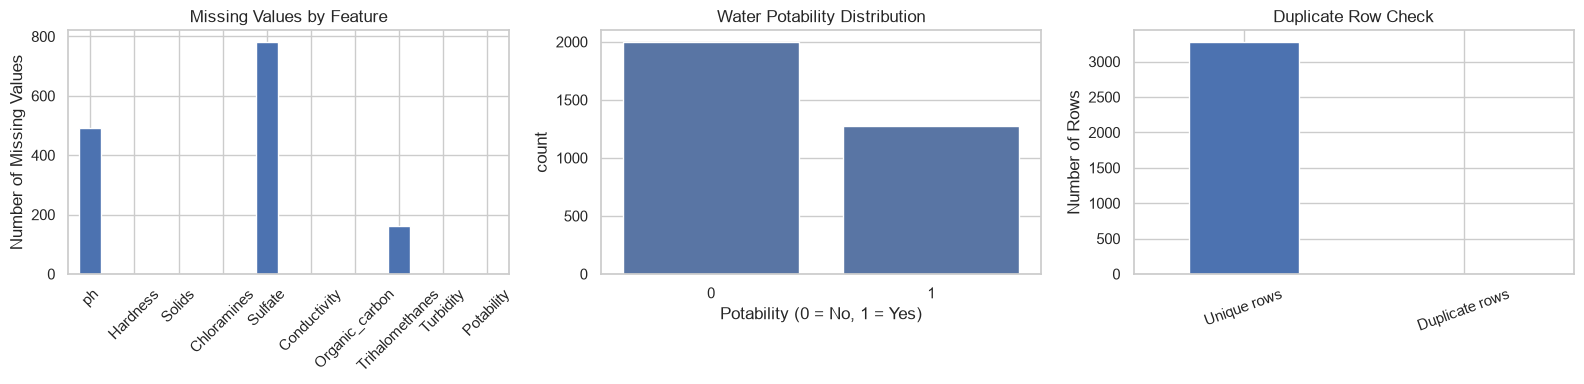

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

df.isnull().sum().plot(kind="bar", ax=axes[0])
axes[0].set_title("Missing Values by Feature")
axes[0].set_ylabel("Number of Missing Values")
axes[0].tick_params(axis="x", rotation=45)

sns.countplot(data=df, x="Potability", ax=axes[1])
axes[1].set_title("Water Potability Distribution")
axes[1].set_xlabel("Potability (0 = No, 1 = Yes)")

duplicate_counts = pd.Series({
    "Unique rows": len(df.drop_duplicates()),
    "Duplicate rows": df.duplicated().sum()
})
duplicate_counts.plot(kind="bar", ax=axes[2])
axes[2].set_title("Duplicate Row Check")
axes[2].set_ylabel("Number of Rows")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [8]:
df_clean = df.copy()

duplicates_before = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Duplicate rows removed:", duplicates_before)
print("Rows after removing duplicates:", len(df_clean))
 
print("\nMissing values after duplicate removal:")
print(df_clean.isnull().sum())

print("\nCleaned dataset preview:")
display(df_clean.head())

Duplicate rows removed: 0
Rows after removing duplicates: 3276

Missing values after duplicate removal:
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

Cleaned dataset preview:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


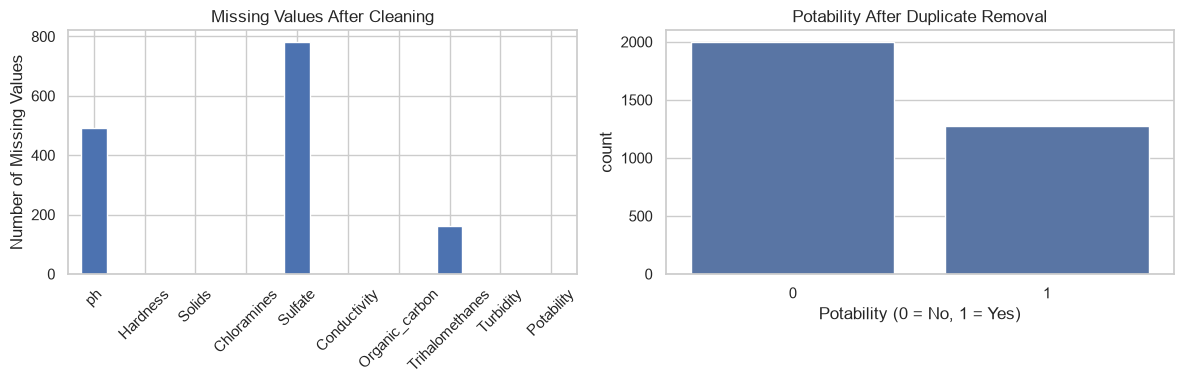

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_clean.isnull().sum().plot(
    kind="bar", ax=axes[0], title="Missing Values After Cleaning"
)
axes[0].set_ylabel("Number of Missing Values")
axes[0].tick_params(axis="x", rotation=45)

sns.countplot(data=df_clean, x="Potability", ax=axes[1])
axes[1].set_title("Potability After Duplicate Removal")
axes[1].set_xlabel("Potability (0 = No, 1 = Yes)")

plt.tight_layout()
plt.show()


In [10]:
from sklearn.model_selection import train_test_split
X = df_clean.drop("Potability", axis=1)
y = df_clean["Potability"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining class distribution:")
print(y_train.value_counts())
print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 2620
Testing samples: 656

Training class distribution:
Potability
0    1598
1    1022
Name: count, dtype: int64

Testing class distribution:
Potability
0    400
1    256
Name: count, dtype: int64


In [11]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Missing values handled successfully.")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)
print("Remaining missing values in training:", 
      int(__import__("numpy").isnan(X_train_scaled).sum()))
print("Remaining missing values in testing:", 
      int(__import__("numpy").isnan(X_test_scaled).sum()))

Missing values handled successfully.
Training data shape: (2620, 9)
Testing data shape: (656, 9)
Remaining missing values in training: 0
Remaining missing values in testing: 0


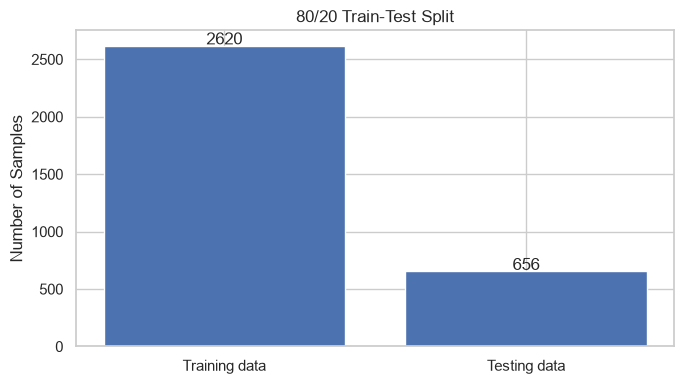

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.bar(
    ["Training data", "Testing data"],
    [len(X_train), len(X_test)]
)

plt.title("80/20 Train-Test Split")
plt.ylabel("Number of Samples")

for i, count in enumerate([len(X_train), len(X_test)]):
    plt.text(i, count + 10, str(count), ha="center")

plt.tight_layout()
plt.show()

In [13]:
from sklearn.neural_network import MLPClassifier

ann_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=300,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=20,
    random_state=42
)

print("ANN model created successfully!")

ANN model created successfully!


In [14]:
ann_model.fit(X_train_scaled, y_train)

print("ANN training completed!")
print("Training iterations:", ann_model.n_iter_)
print("Best validation score:", round(ann_model.best_validation_score_, 4))

ANN training completed!
Training iterations: 33
Best validation score: 0.6947


In [15]:
y_pred = ann_model.predict(X_test_scaled)
y_prob = ann_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully!")
print("First 10 actual labels:", y_test.iloc[:10].tolist())
print("First 10 predicted labels:", y_pred[:10].tolist())

Predictions generated successfully!
First 10 actual labels: [1, 0, 0, 0, 0, 0, 0, 0, 1, 1]
First 10 predicted labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy:  {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy:  0.6540 (65.40%)
Precision: 0.6179
Recall:    0.2969
F1-score:  0.4011
ROC-AUC:   0.6676

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.88      0.76       400
           1       0.62      0.30      0.40       256

    accuracy                           0.65       656
   macro avg       0.64      0.59      0.58       656
weighted avg       0.64      0.65      0.62       656



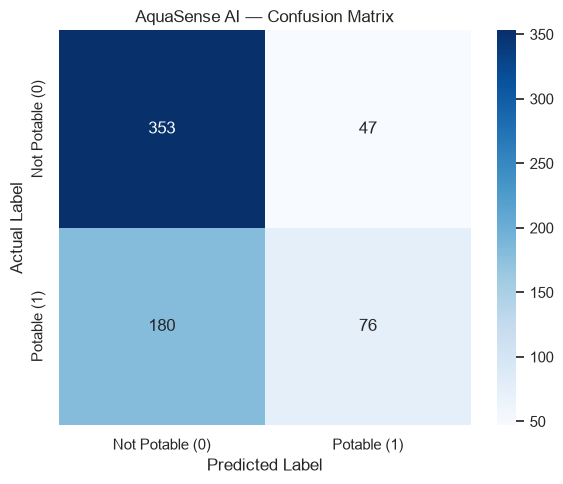

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Potable (0)", "Potable (1)"],
    yticklabels=["Not Potable (0)", "Potable (1)"]
)

plt.title("AquaSense AI — Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

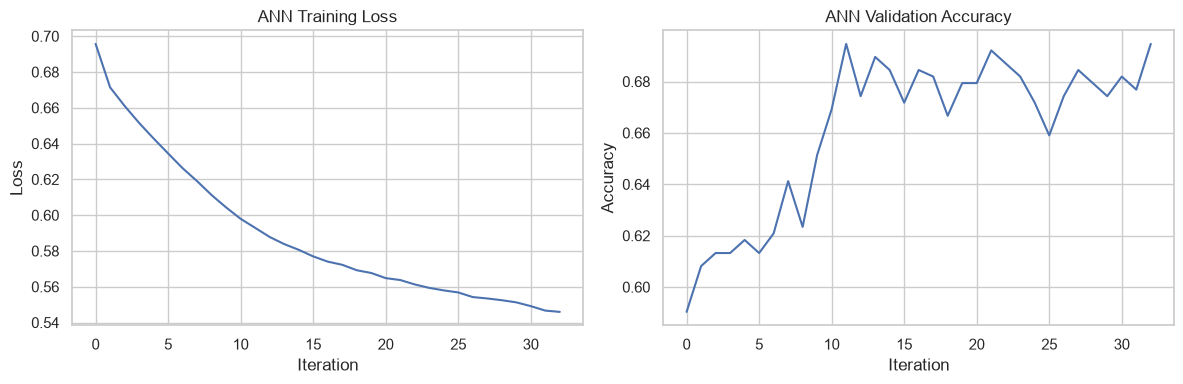

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Training loss across iterations
axes[0].plot(ann_model.loss_curve_)
axes[0].set_title("ANN Training Loss")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Loss")

axes[1].plot(ann_model.validation_scores_)
axes[1].set_title("ANN Validation Accuracy")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Accuracy")

plt.tight_layout()
plt.show()

In [19]:
import joblib
import os

os.makedirs("AquaSense_AI", exist_ok=True)

joblib.dump(ann_model, "AquaSense_AI/water_potability_ann.pkl")
joblib.dump(imputer, "AquaSense_AI/water_potability_imputer.pkl")
joblib.dump(scaler, "AquaSense_AI/water_potability_scaler.pkl")
joblib.dump(list(X.columns), "AquaSense_AI/water_potability_features.pkl")

print("All model files saved successfully!")

All model files saved successfully!


In [20]:
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

threshold_results = []

for threshold in np.arange(0.20, 0.61, 0.05):
    predictions = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": round(accuracy_score(y_test, predictions), 4),
        "Precision": round(precision_score(y_test, predictions, zero_division=0), 4),
        "Recall": round(recall_score(y_test, predictions, zero_division=0), 4),
        "F1-score": round(f1_score(y_test, predictions, zero_division=0), 4)
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df)

,Threshold,Accuracy,Precision,Recall,F1-score
0,0.20,0.4207,0.4022,0.9961,0.5730
1,0.25,0.4405,0.4077,0.9570,0.5718
2,0.30,0.4787,0.4210,0.8945,0.5725
3,0.35,0.5701,0.4699,0.7930,0.5901
4,0.40,0.6204,0.5110,0.6328,0.5654
5,0.45,0.6479,0.5635,0.4336,0.4901
6,0.50,0.6540,0.6179,0.2969,0.4011
7,0.55,0.6616,0.7297,0.2109,0.3273
8,0.60,0.6662,0.8776,0.1680,0.2820


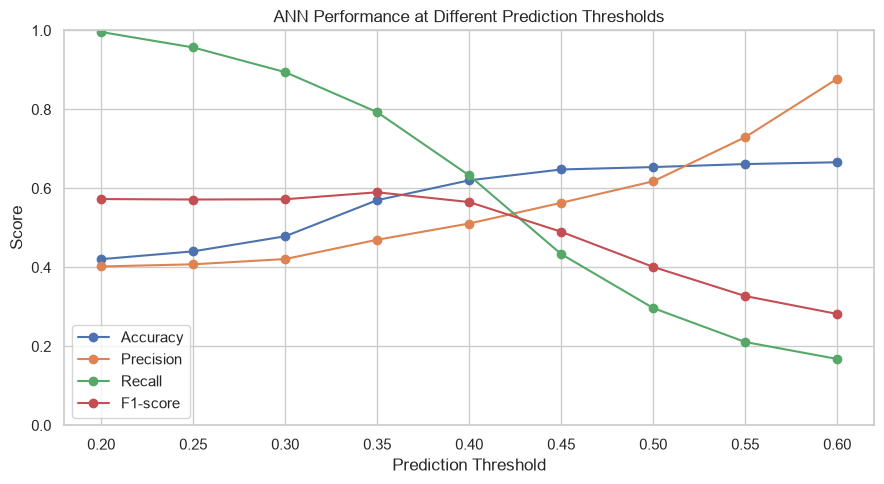

In [21]:
plt.figure(figsize=(9, 5))

for metric in ["Accuracy", "Precision", "Recall", "F1-score"]:
    plt.plot(
        threshold_df["Threshold"],
        threshold_df[metric],
        marker="o",
        label=metric
    )

plt.title("ANN Performance at Different Prediction Thresholds")
plt.xlabel("Prediction Threshold")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [22]:
best_row = threshold_df.loc[threshold_df["F1-score"].idxmax()]
best_threshold = float(best_row["Threshold"])

print("Best threshold based on F1-score:", best_threshold)
print("\nMetrics at the selected threshold:")
print(best_row)

y_pred_tuned = (y_prob >= best_threshold).astype(int)

print("\nUpdated classification report:")
print(classification_report(y_test, y_pred_tuned, zero_division=0))

print("Updated confusion matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Best threshold based on F1-score: 0.35

Metrics at the selected threshold:
Threshold    0.3500
Accuracy     0.5701
Precision    0.4699
Recall       0.7930
F1-score     0.5901
Name: 3, dtype: float64

Updated classification report:
              precision    recall  f1-score   support

           0       0.76      0.43      0.55       400
           1       0.47      0.79      0.59       256

    accuracy                           0.57       656
   macro avg       0.62      0.61      0.57       656
weighted avg       0.65      0.57      0.56       656

Updated confusion matrix:
[[171 229]
 [ 53 203]]


In [23]:
import joblib
import os

os.makedirs("AquaSense_AI", exist_ok=True)

joblib.dump(ann_model, "AquaSense_AI/water_potability_ann.pkl")
joblib.dump(imputer, "AquaSense_AI/water_potability_imputer.pkl")
joblib.dump(scaler, "AquaSense_AI/water_potability_scaler.pkl")
joblib.dump(list(X.columns), "AquaSense_AI/water_potability_features.pkl")
joblib.dump(best_threshold, "AquaSense_AI/water_potability_threshold.pkl")

print("All AquaSense AI model files saved successfully!")
print("Selected exploratory threshold:", best_threshold)
print("Files:", os.listdir("AquaSense_AI"))

All AquaSense AI model files saved successfully!
Selected exploratory threshold: 0.35
Files: ['water_potability.csv', 'water_potability_ann.pkl', 'water_potability_features.pkl', 'water_potability_imputer.pkl', 'water_potability_scaler.pkl', 'water_potability_threshold.pkl']


In [24]:
import flask
print("Flask version:", flask.__version__)

Flask version: 3.1.3


C:\Users\syeda\AppData\Local\Temp\ipykernel_8796\1179009207.py:2: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in Flask 3.2. Use feature detection or 'importlib.metadata.version("flask")' instead.
  print("Flask version:", flask.__version__)


In [25]:
import os

project_folder = os.path.abspath("AquaSense_AI")
print("Project folder:", project_folder)
print("\nFiles available:")

for file in os.listdir(project_folder):
    print(file)

Project folder: C:\Users\syeda\AquaSense_AI

Files available:
water_potability.csv
water_potability_ann.pkl
water_potability_features.pkl
water_potability_imputer.pkl
water_potability_scaler.pkl
water_potability_threshold.pkl


In [28]:

from pathlib import Path

app_code = """from flask import Flask, request, render_template
import joblib
import numpy as np
from pathlib import Path

app = Flask(__name__)
BASE = Path(__file__).resolve().parent

model = joblib.load(BASE / "water_potability_ann.pkl")
imputer = joblib.load(BASE / "water_potability_imputer.pkl")
scaler = joblib.load(BASE / "water_potability_scaler.pkl")
features = joblib.load(BASE / "water_potability_features.pkl")
threshold = joblib.load(BASE / "water_potability_threshold.pkl")

LABELS = {
    "ph": "pH",
    "Hardness": "Hardness",
    "Solids": "Total dissolved solids",
    "Chloramines": "Chloramines",
    "Sulfate": "Sulfate",
    "Conductivity": "Conductivity",
    "Organic_carbon": "Organic carbon",
    "Trihalomethanes": "Trihalomethanes",
    "Turbidity": "Turbidity",
}

@app.route("/", methods=["GET", "POST"])
def home():
    values = {}
    result = None
    error = None

    if request.method == "POST":
        try:
            row = []
            for feature in features:
                raw = request.form.get(feature, "").strip()
                values[feature] = raw
                row.append(np.nan if raw == "" else float(raw))

            X = np.array(row, dtype=float).reshape(1, -1)
            X = imputer.transform(X)
            X = scaler.transform(X)

            probability = float(model.predict_proba(X)[0, 1])
            label = int(probability >= threshold)

            result = {
                "label": label,
                "title": "Class 1: Potable" if label == 1 else "Class 0: Not Potable",
                "probability": round(probability * 100, 2),
            }
        except (ValueError, TypeError):
            error = "Please enter valid numbers, or leave unknown values blank."

    return render_template(
        "index.html",
        fields=features,
        labels=LABELS,
        values=values,
        result=result,
        error=error,
    )

if __name__ == "__main__":
    app.run(host="127.0.0.1", port=5000, debug=False)
"""

(project_folder / "app.py").write_text(app_code, encoding="utf-8")

print("app.py created successfully!")


app.py created successfully!


In [3]:

from pathlib import Path

# 1. Define the project folder
project_folder = Path("AquaSense_AI").resolve()

# If the folder is not found in the current directory, check common locations
if not project_folder.exists():
    possible_folder = Path.cwd() / "AquaSense_AI"
    if possible_folder.exists():
        project_folder = possible_folder

templates_folder = project_folder / "templates"
templates_folder.mkdir(parents=True, exist_ok=True)

# 2. Create the updated website
html_code = """<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>AquaSense AI</title>

<style>
*{box-sizing:border-box}
body{margin:0;background:#071521;color:#edfaff;font-family:Segoe UI,Arial,sans-serif}
header{padding:22px 7%;border-bottom:1px solid #294958;display:flex;justify-content:space-between;align-items:center}
.brand{font-size:23px;font-weight:800}
.brand span{color:#48e0d0}
.tag{color:#48e0d0;border:1px solid #286b70;border-radius:30px;padding:8px 12px;font-size:12px}
main{max-width:1400px;margin:42px auto;padding:0 22px}
.eyebrow{color:#48e0d0;text-transform:uppercase;letter-spacing:2px;font-size:12px}
h1{font-size:clamp(32px,5vw,48px);margin:12px 0}
p{color:#a9c3d0;line-height:1.7}
.layout{display:grid;grid-template-columns:1.7fr .8fr;gap:26px}
.card{background:#102635;border:1px solid #294958;border-radius:20px;padding:30px}
h2{margin-top:0;font-size:25px}
.fields{display:grid;grid-template-columns:1fr 1fr;gap:20px 22px}
label{display:block;margin-bottom:9px;font-size:15px}
input{width:100%;padding:15px;background:#081b28;color:white;border:1px solid #345363;border-radius:12px;font-size:16px}
input:focus{outline:2px solid #48e0d0}
button{width:100%;padding:16px;margin-top:24px;border:0;border-radius:11px;background:linear-gradient(90deg,#48e0d0,#63a8ff);font-weight:800;font-size:15px;cursor:pointer}
.result{margin-top:20px;background:#081b28;border:1px solid #48e0d0;border-radius:14px;padding:20px}
.result h3{font-size:21px}
.number{font-size:28px;font-weight:bold}
.feature{padding:15px 0}
.feature small{display:block;color:#a9c3d0;line-height:1.7;margin-top:10px;font-size:15px}
.error{color:#ffb5b5}
footer{text-align:center;color:#8aa8b7;font-size:12px;padding:25px}
@media(max-width:780px){.layout{grid-template-columns:1fr}}
@media(max-width:480px){.fields{grid-template-columns:1fr}header{padding:18px}main{margin:25px auto}.card{padding:18px}}
</style>
</head>

<body>
<header>
    <div class="brand">💧 AquaSense <span>AI</span></div>
    <div class="tag">ANN MODEL</div>
</header>

<main>
    <div class="eyebrow">Intelligent water analysis</div>
    <h1>Understand your water.<br>
        <span style="color:#48e0d0">Explore the data.</span>
    </h1>
    <p>Enter water-quality measurements for an educational prediction from a trained artificial neural network.</p>

    <div class="layout">
        <section class="card">
            <h2>Water parameters</h2>
            <p>Enter measurements in the dataset's units. Leave unavailable values blank.</p>

            <form method="POST">
                <div class="fields">
                    {% for field in fields %}
                    <div>
                        <label for="{{ field }}">{{ labels[field] }}</label>
                        <input id="{{ field }}"
                               name="{{ field }}"
                               type="number"
                               step="any"
                               placeholder="Enter value"
                               value="{{ values.get(field, '') }}">
                    </div>
                    {% endfor %}
                </div>
                <button type="submit">✦ Analyze Water Data</button>
            </form>

            {% if error %}
            <p class="error">{{ error }}</p>
            {% endif %}

            {% if result %}
            <div class="result">
                <h3>{{ result.title }}</h3>
                <div class="number">{{ result.probability }}%</div>
                <p>Model-estimated probability for class 1. This is not a certified water-safety result.</p>
            </div>
            {% endif %}
        </section>

        <aside class="card">
            <h2>Safety first</h2>
            <div class="feature">
                ⚠️
                <small>
                    Do not use this model to decide whether water is safe to drink.
                    This is an educational machine-learning prediction, not a
                    certified water-quality test. Appropriate laboratory testing
                    is required to assess drinking-water safety.
                </small>
            </div>
        </aside>
    </div>
</main>

<footer>AquaSense AI · Educational machine-learning project · Local demo</footer>
</body>
</html>
"""

# 3. Save the updated HTML file
html_path = templates_folder / "index.html"
html_path.write_text(html_code, encoding="utf-8")

print("Updated website template saved successfully!")
print("Project folder:", project_folder)
print("HTML file:", html_path)


Updated website template saved successfully!
Project folder: C:\Users\syeda\AquaSense_AI
HTML file: C:\Users\syeda\AquaSense_AI\templates\index.html


In [4]:
import subprocess
import sys

flask_process = subprocess.Popen(
    [sys.executable, str(project_folder / "app.py")],
    cwd=str(project_folder)
)

print("Flask is starting...")
print("Open http://127.0.0.1:5000 in Chrome.")

Flask is starting...
Open http://127.0.0.1:5000 in Chrome.


In [5]:

from pathlib import Path
import os

project_folder = Path("AquaSense_AI").resolve()

print("Project folder:", project_folder)
print("\nRequired files:")

required_files = [
    "app.py",
    "water_potability_ann.pkl",
    "water_potability_imputer.pkl",
    "water_potability_scaler.pkl",
    "water_potability_features.pkl",
    "water_potability_threshold.pkl",
    "templates/index.html"
]

for name in required_files:
    path = project_folder / name
    print(("OK      " if path.exists() else "MISSING "), name)


Project folder: C:\Users\syeda\AquaSense_AI

Required files:
OK       app.py
OK       water_potability_ann.pkl
OK       water_potability_imputer.pkl
OK       water_potability_scaler.pkl
OK       water_potability_features.pkl
OK       water_potability_threshold.pkl
OK       templates/index.html


In [ ]:

import runpy
import os

os.chdir(project_folder)
runpy.run_path(str(project_folder / "app.py"), run_name="__main__")


 * Serving Flask app 'app'
 * Debug mode: off


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit
